---
Institute : Burkina Institute of Technology (BIT)

Class: Artifi cial Intelligence

Level: Master 2

EU : Advanced Machine Learning

EC: Reinforcement Learning

Date : August 2025

Teacher : Dr Ouedraogo Moïse  

---

# 📘 TP 1 : Gridworld env – Policy Evaluation, Iteration & Value Iteration 📘
---
In this notebook, you will manipulate a **Gridworld** environment as part of a **Markov Decision Process (MDP)**.

You will learn how to :
- Model an environment in terms of states, actions, rewards and transitions.
- Implement and evaluate **policies**.
- Use classic MDP solving algorithms: **Policy evaluation**, **Policy iteration**, and **Value iteration**.

This notebook follows on from the MDP theory session. Make sure you understand the following concepts:
- States, actions, rewards, transitions
- Policy
- Value of a state (V)
- Value of an action (Q)
---




In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Define Gridworld Environment
class GridworldEnv:
    def __init__(self, grid_size=(4, 4), terminal_states=[(0, 0), (3, 3)], gamma=0.9):
        self.grid_size = grid_size
        self.terminal_states = terminal_states
        self.gamma = gamma
        self.actions = ['up', 'down', 'left', 'right']
        self.states = [(i, j) for i in range(grid_size[0]) for j in range(grid_size[1])]
        self.P = self._build_transition_probabilities()

    def is_terminal(self, state):
        return state in self.terminal_states

    def get_next_state(self, state, action):
        if self.is_terminal(state):
            return state
        i, j = state
        if action == 'up':
            return (max(i - 1, 0), j)
        elif action == 'down':
            return (min(i + 1, self.grid_size[0] - 1), j)
        elif action == 'left':
            return (i, max(j - 1, 0))
        elif action == 'right':
            return (i, min(j + 1, self.grid_size[1] - 1))
        return state

    def get_reward(self, state, action, next_state):
        if next_state in self.terminal_states:
            return 0
        else:
            return -1

    def _build_transition_probabilities(self):
        P = {}
        for state in self.states:
            P[state] = {}
            for action in self.actions:
                next_state = self.get_next_state(state, action)
                reward = self.get_reward(state, action, next_state)
                P[state][action] = [(1.0, next_state, reward, self.is_terminal(next_state))] # (prob, next_state, reward, is_terminal)
        return P

In [2]:
env=GridworldEnv()
env.P

{(0, 0): {'up': [(1.0, (0, 0), 0, True)],
  'down': [(1.0, (0, 0), 0, True)],
  'left': [(1.0, (0, 0), 0, True)],
  'right': [(1.0, (0, 0), 0, True)]},
 (0, 1): {'up': [(1.0, (0, 1), -1, False)],
  'down': [(1.0, (1, 1), -1, False)],
  'left': [(1.0, (0, 0), 0, True)],
  'right': [(1.0, (0, 2), -1, False)]},
 (0, 2): {'up': [(1.0, (0, 2), -1, False)],
  'down': [(1.0, (1, 2), -1, False)],
  'left': [(1.0, (0, 1), -1, False)],
  'right': [(1.0, (0, 3), -1, False)]},
 (0, 3): {'up': [(1.0, (0, 3), -1, False)],
  'down': [(1.0, (1, 3), -1, False)],
  'left': [(1.0, (0, 2), -1, False)],
  'right': [(1.0, (0, 3), -1, False)]},
 (1, 0): {'up': [(1.0, (0, 0), 0, True)],
  'down': [(1.0, (2, 0), -1, False)],
  'left': [(1.0, (1, 0), -1, False)],
  'right': [(1.0, (1, 1), -1, False)]},
 (1, 1): {'up': [(1.0, (0, 1), -1, False)],
  'down': [(1.0, (2, 1), -1, False)],
  'left': [(1.0, (1, 0), -1, False)],
  'right': [(1.0, (1, 2), -1, False)]},
 (1, 2): {'up': [(1.0, (0, 2), -1, False)],
  'down'

### Definition of a policy

A **policy** (`policy`) is a function that gives the probability of choosing each action in each state.

In this example, we'll start with a **uniform random policy**, i.e. in each state, all actions have the same probability of being chosen.

**To do**:
- Observe the structure of the policy.
- Modify it to test other policies (for example, always go right, or prefer certain actions).





## Policy definition

In [ ]:

# Define a uniform random policy
def create_uniform_policy(states, actions):
    policy = {}
    for state in states:
        policy[state] = {a: 1 / len(actions) for a in actions}
    return policy


## Policy evaluation Function

In [ ]:
def policy_evaluation(env, policy, theta=1e-4):
        V = {s: 0 for s in env.states}
        i=0
        while True:
            i+=1
            delta = 0
            for state in env.states:
                if env.is_terminal(state):
                    continue
                v = V[state]
                new_v = 0
                for action, action_prob in policy[state].items():
                    # Use the P dictionary to get transitions
                    for prob, next_state, reward, _ in env.P[state][action]:
                         new_v += action_prob * prob * (reward + env.gamma * V[next_state])
                V[state] = new_v
                delta = max(delta, abs(v - new_v))
            if delta < theta:
                print("Terminate after " + str(i) + " iterations")
                break
        return V

In [ ]:

# Evaluate policy
policy = create_uniform_policy(env.states, env.actions)
value_function = policy_evaluation(env, policy)


### Plot value functions

In [ ]:
# Plot value functions
def plot_value_function(V_dict, title):
    # Convert value function to grid for visualization
    V_grid = np.zeros(env.grid_size)
    for (i, j), v in V_dict.items():
        V_grid[i, j] = v

    # Plot the value function
    plt.figure(figsize=(6, 6))
    plt.imshow(V_grid, cmap='coolwarm', interpolation='none')
    for i in range(env.grid_size[0]):
        for j in range(env.grid_size[1]):
            plt.text(j, i, f'{V_grid[i, j]:.1f}', ha='center', va='center', color='black')
    plt.title(title)
    plt.colorbar()
    plt.show()

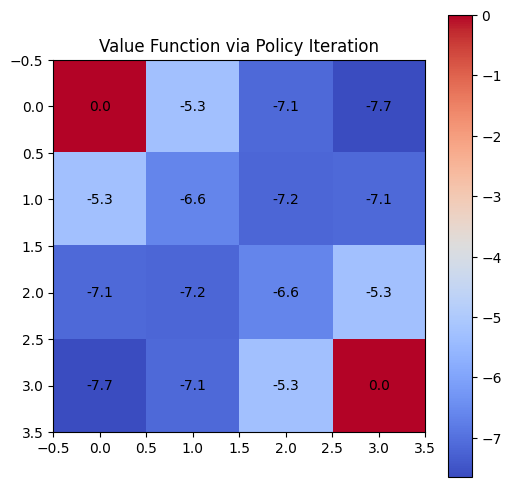

In [ ]:
plot_value_function(value_function, "Value Function via Policy Iteration")

## Policy Improvement function

In [ ]:
# Policy Improvement
def policy_improvement(V, env):
    new_policy = {}
    for state in env.states:
        if env.is_terminal(state):
            new_policy[state] = {a: 0.0 for a in env.actions}
            continue
        action_values = {}
        for action in env.actions:
            # Use the P dictionary to get transitions
            for prob, next_state, reward, _ in env.P[state][action]:
                action_values[action] = prob * (reward + env.gamma * V[next_state]) # Assuming deterministic transitions for simplicity in this function
        best_action = max(action_values, key=action_values.get)
        new_policy[state] = {a: 1.0 if a == best_action else 0.0 for a in env.actions}
    return new_policy

## Policy Iteration

In [ ]:

# Policy Iteration
def policy_iteration(env, theta=1e-4):
    policy = create_uniform_policy(env.states, env.actions)
    #i=0
    while True:
        #i+=1
        V = policy_evaluation(env,policy, theta)
        new_policy = policy_improvement(V, env)
        if new_policy == policy:
            #print("Terminate after " + str(i) + " iterations")
            break
        policy = new_policy
    return policy, V

optimal_policy, optimal_value = policy_iteration(env)


Terminate after 41 iterations
Terminate after 3 iterations
Terminate after 4 iterations


## Plot Optimal Value Function via Policy Iteration

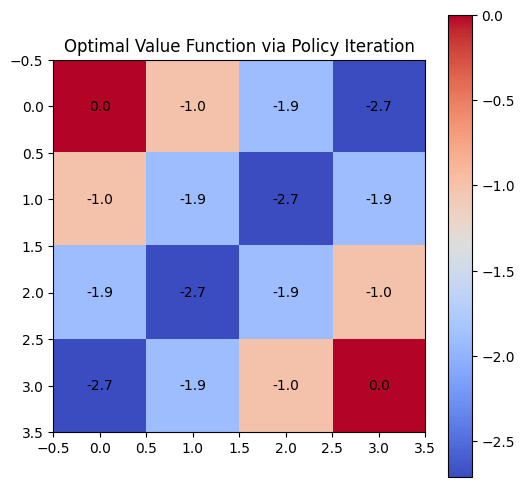

In [ ]:
plot_value_function(optimal_value, "Optimal Value Function via Policy Iteration")

## Value Iteration function

In [ ]:
# Value Iteration
def value_iteration(env, theta=1e-4):
    V = {s: 0 for s in env.states}
    i=0
    while True:
        i+=1
        delta = 0
        for state in env.states:
            if env.is_terminal(state):
                continue
            v = V[state]
            action_values = []
            for action in env.actions:
                # Use the P dictionary to get transitions
                for prob, next_state, reward, _ in env.P[state][action]:
                    action_values.append(prob * (reward + env.gamma * V[next_state])) # Assuming deterministic transitions for simplicity in this function
            V[state] = max(action_values)
            delta = max(delta, abs(v - V[state]))
        if delta < theta:
            print("Terminate after " + str(i) + " iterations")
            break
    policy = {}
    for state in env.states:
        if env.is_terminal(state):
            policy[state] = {a: 0.0 for a in env.actions}
            continue
        action_values = {}
        for action in env.actions:
             # Use the P dictionary to get transitions
            for prob, next_state, reward, _ in env.P[state][action]:
                action_values[action] = prob * (reward + env.gamma * V[next_state]) # Assuming deterministic transitions for simplicity in this function
        best_action = max(action_values, key=action_values.get)
        policy[state] = {a: 1.0 if a == best_action else 0.0 for a in env.actions}
    return policy, V

vi_policy, vi_value = value_iteration(env)

Terminate after 4 iterations


### Plot Optimal Value Function via Value Iteration

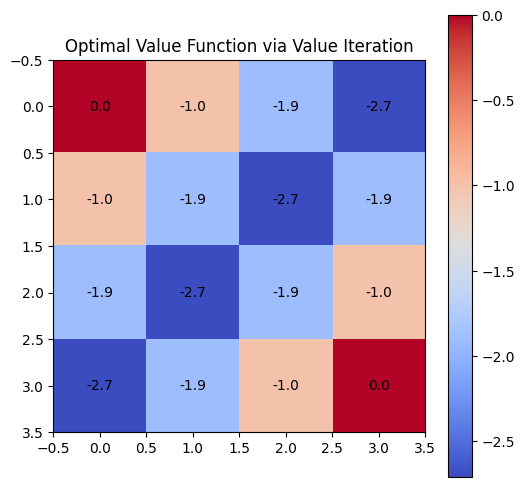

In [ ]:
plot_value_function(vi_value, "Optimal Value Function via Value Iteration")

In [ ]:
# Function to transform policy into display grid
def get_policy_grid(policy, grid_size):
    policy_symbols = np.full(grid_size, '', dtype=object)
    arrows = {'up': '↑', 'down': '↓', 'left': '←', 'right': '→'}

    for (i, j), action_probs in policy.items():
        if sum(action_probs.values()) == 0:
            policy_symbols[i, j] = '■'  # état terminal
        else:
            best_action = max(action_probs, key=action_probs.get)
            policy_symbols[i, j] = arrows[best_action]
    return policy_symbols

## Plot Optimal Policy via Policy Iteration

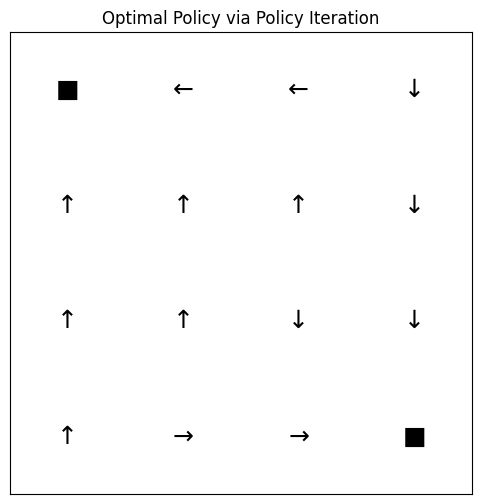

In [ ]:
# Generate and display policy
policy_display = get_policy_grid(optimal_policy, env.grid_size)

plt.figure(figsize=(6, 6))
plt.imshow(np.zeros(env.grid_size), cmap='Greys', vmin=0, vmax=1)  # fond vide

for i in range(env.grid_size[0]):
    for j in range(env.grid_size[1]):
        plt.text(j, i, policy_display[i, j], ha='center', va='center', fontsize=18, color='black')

plt.title("Optimal Policy via Policy Iteration")
plt.xticks([])
plt.yticks([])
plt.show()

## Plot Optimal Policy via Value Iteration

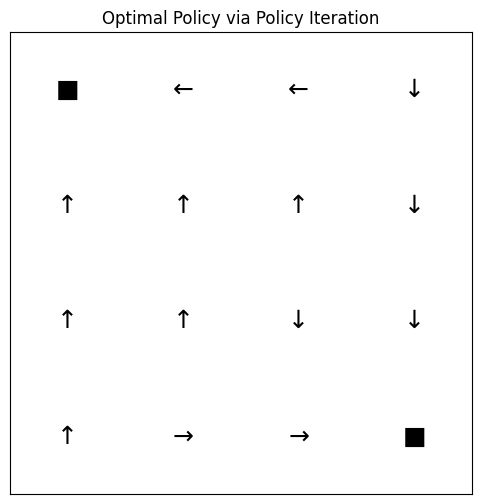

In [ ]:
# Generate and display policy
policy_display = get_policy_grid(vi_policy, env.grid_size)

plt.figure(figsize=(6, 6))
plt.imshow(np.zeros(env.grid_size), cmap='Greys', vmin=0, vmax=1)  # fond vide

for i in range(env.grid_size[0]):
    for j in range(env.grid_size[1]):
        plt.text(j, i, policy_display[i, j], ha='center', va='center', fontsize=18, color='black')

plt.title("Optimal Policy via Policy Iteration")
plt.xticks([])
plt.yticks([])
plt.show()

---

## Additional exercises

### Exercise 1 - Modify the policy
Modify the current policy so that the agent behaves in a **deterministic** way: it always goes in the same direction (e.g. always to the right, or always down).

- Implement this policy in the policy definition cell.
- Observe the values of the policy evaluation.
- What is the value of states close to the edge? Why or why not?

---

### Exercise 2 - Custom Gridworld
Create your own **Gridworld** with different dimensions or by modifying the rewards.

- Add new walls or boxes with specific rewards.
- What's the best policy in this new world?

---

### Exercise 3 - Comparing algorithms
Compare the results obtained with :
- Policy evaluation
- Policy iteration
- Value iteration

Analyze:
- Number of iterations required
- Policy obtained
- Value stability

---

### Exercise 4 - Visualization
Add a code that displays the **policy as arrows** in the grid. This makes it easier to visualize the agent's behavior.

*(Hint: use symbols like ↑ ↓ ← → to represent actions in each state.)*

---

**Bonus**: What happens if you change the `gamma` reduction factor? Test several values (`0.1`, `0.5`, `0.9`, `0.99`) and discuss their effect.

---

### Exercise 5 - Stochastic policy

In real-life environments, decisions are not always deterministic. A **stochastic policy** assigns a probability distribution over the possible actions in each state.

**To do**:
- Change the current policy to **non-uniform stochastic** :
  - For example: 60% go right, 30% down, 10% left in each state.
- Implement this policy in the code.
- Compare the values obtained with those of a deterministic policy.
- Observe whether the policy converges and is stable.

**Questions**:
- What is the impact of stochastics on agent stability?
- Can a stochastic policy be optimal?

---

### Exercise 6 - Obstacles and inaccessible states

Add **obstacles** to the Gridworld (boxes that the agent cannot cross).

**To do**:
- Choose certain squares to turn into walls (obstacles).
- Modify the environment so that the agent cannot cross them.
- Replay the value or policy evaluation iteration.

**Questions**:
- How do obstacles influence the value of neighboring states?
- What optimal strategy does the agent learn in the presence of obstacles?

---

### Bonus exercise - Optimal stochastic policy

Try to **manually** design a stochastic policy that maximizes long-term reward, despite the uncertainty of transitions or the presence of obstacles.

- Justify your choice of probability distribution.
- Compare your policy with the results of the policy iteration.

---


